In [1]:
# Cell 1: Import required libraries
import os, json, time, random, shutil, yaml
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from ultralytics import YOLO

In [2]:
# Cell 2: Setup & verify Dataset

# GPU check
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

# Paths
YOLO_DIR = Path("../data/processed/cardd_yolo")
MODELS_DIR = Path("../models/yolo")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS = Path("../reports/metrics")
REPORTS.mkdir(parents=True, exist_ok=True)
Path("../reports/figures/detection").mkdir(parents=True, exist_ok=True)
DATA_YAML = YOLO_DIR / "data.yaml"

# verify data.yaml
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)

print(f"\ndata.yaml loaded:")
print(cfg)
print(f"\nClasses: {cfg['names']}")
print(f"Num classes: {cfg['nc']}")

CLASS_NAMES = list(cfg["names"])

# Verify counts
for split in ["train", "val", "test"]:
    n = len(list((YOLO_DIR / "images" / split).glob("*.jpg")))
    print(f"  {split}: {n} images")

cuda

data.yaml loaded:
{'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 6, 'names': ['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']}

Classes: ['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']
Num classes: 6
  train: 2816 images
  val: 810 images
  test: 374 images


In [3]:
# Cell 3: Load YOLOv8s
model = YOLO("yolov8s.pt")
print("YOLOv8s loaded (pretrained on COCO 80 classes).")
print(f"Total params: {sum(p.numel() for p in model.model.parameters()) / 1e6:.2f}M")

YOLOv8s loaded (pretrained on COCO 80 classes).
Total params: 11.17M


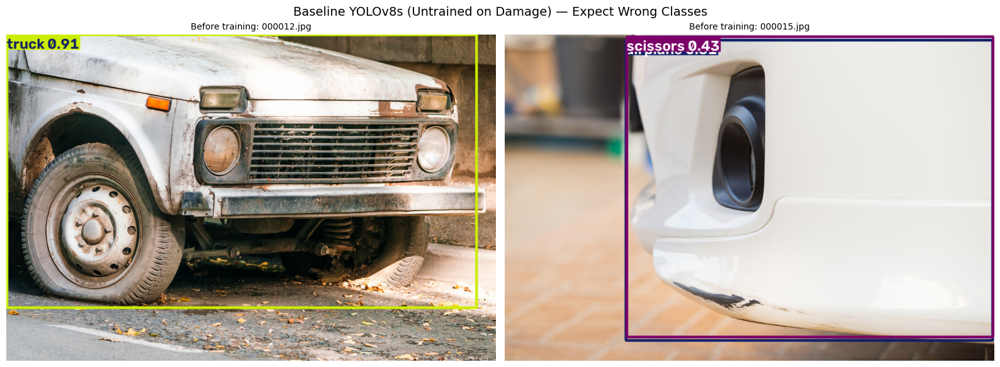


These detections are COCO classes (car, person, etc.) — the model has NOT learned damage yet.


In [4]:
# Cell 4: Baseline inference — see how badly pretrained YOLO does on damage
# Pick 2 test images (one close-up, one whole car)
test_imgs = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))[:2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Baseline YOLOv8s (Untrained on Damage) — Expect Wrong Classes", fontsize=14)

for ax, img_path in zip(axes, test_imgs):
    results = model.predict(str(img_path), conf=0.25, verbose=False)
    for r in results:
        im_array = r.plot()
        ax.imshow(cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Before training: {img_path.name}", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.savefig("../reports/figures/yolo_baseline.png", dpi=110)
plt.show()

print("\nThese detections are COCO classes (car, person, etc.) — the model has NOT learned damage yet.")

In [5]:
# Cell 5: Training Config
TRAINING_CONFIG = {
    "data": str(DATA_YAML),
    "epochs": 50,
    "imgsz": 640,
    "batch": 8,           # 4GB VRAM safe
    "device": 0,          # GPU
    "workers": 4,
    "patience": 15,       # early stopping
    "save": True,
    "save_period": 10,    # checkpoint every 10 epochs
    "project": str(MODELS_DIR),
    "name": "yolov8s_cardd",
    "exist_ok": True,
    "pretrained": True,
    "optimizer": "auto",
    "lr0": 0.01,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    # Augmentation
    "hsv_h": 0.015,
    "hsv_s": 0.7,
    "hsv_v": 0.4,
    "degrees": 10.0,
    "translate": 0.1,
    "scale": 0.5,
    "shear": 2.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.5,
    "mosaic": 1.0,
    "mixup": 0.1,
    "copy_paste": 0.1,
    # Validation
    "val": True,
    "plots": True,
    "verbose": True,
}

print("Training config:")
for k, v in TRAINING_CONFIG.items():
    print(f"  {k}: {v}")

Training config:
  data: ..\data\processed\cardd_yolo\data.yaml
  epochs: 50
  imgsz: 640
  batch: 8
  device: 0
  workers: 4
  patience: 15
  save: True
  save_period: 10
  project: ..\models\yolo
  name: yolov8s_cardd
  exist_ok: True
  pretrained: True
  optimizer: auto
  lr0: 0.01
  lrf: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  warmup_epochs: 3.0
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 10.0
  translate: 0.1
  scale: 0.5
  shear: 2.0
  perspective: 0.0
  flipud: 0.0
  fliplr: 0.5
  mosaic: 1.0
  mixup: 0.1
  copy_paste: 0.1
  val: True
  plots: True
  verbose: True


In [6]:
# Cell 6: Start Training (already completed: 50 epochs, 1.193 hours)
# Keep False so Restart & Run All never retrains. Set True only if you really want to retrain.
RUN_TRAINING = False

if RUN_TRAINING:
    results = model.train(**TRAINING_CONFIG)
    print("\nTraining complete.")
    print(f"Best weights: {results.save_dir}")
else:
    print("Training skipped (already completed). Using saved weights from Cell 7.")

Training skipped (already completed). Using saved weights from Cell 7.


In [7]:
# Cell 7: Locate and copy YOLO weights to the correct models/ directory

# Search for weights (Ultralytics saves to CWD-relative runs/)
candidates = [
    Path("./runs/models/yolo/yolov8s_cardd"),
    Path("../notebooks/runs/models/yolo/yolov8s_cardd"),
    Path("runs/detect/yolov8s_cardd"),
]

source = None
for c in candidates:
    if (c / "weights" / "best.pt").exists():
        source = c
        print(f"Found weights at: {c.resolve()}")
        break

if source is None:
    print("Weights not found. Searching entire project...")
    for p in Path(".").rglob("best.pt"):
        print(f"  Found: {p.resolve()}")

# Copy to correct location
correct_path = Path("../models/yolo/yolov8s_cardd")
correct_path.mkdir(parents=True, exist_ok=True)

if source:
    for item in source.iterdir():
        dst = correct_path / item.name
        if item.is_file():
            shutil.copy(item, dst)
        elif item.is_dir():
            shutil.copytree(item, dst, dirs_exist_ok=True)
    print(f"\nCopied to: {correct_path.resolve()}")

# Verify
weights_path = correct_path / "weights" / "best.pt"
print(f"\nBest weights at: {weights_path.resolve()}")
print(f"Exists: {weights_path.exists()}")
if weights_path.exists():
    print(f"Size: {weights_path.stat().st_size / 1e6:.1f} MB")

Found weights at: C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\notebooks\runs\models\yolo\yolov8s_cardd

Copied to: C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\models\yolo\yolov8s_cardd

Best weights at: C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\models\yolo\yolov8s_cardd\weights\best.pt
Exists: True
Size: 22.5 MB


In [8]:
# Cell 8: Evaluate on test set (standard Ultralytics evaluation, run once)
BEST_WEIGHTS = Path("../models/yolo/yolov8s_cardd/weights/best.pt")

model_best = YOLO(str(BEST_WEIGHTS))
test_metrics = model_best.val(data=str(DATA_YAML), split="test", verbose=False)

print("--- Test Set Metrics ---")
print(f"mAP@0.5:      {test_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {test_metrics.box.map:.4f}")
print(f"Precision:    {test_metrics.box.mp:.4f}")
print(f"Recall:       {test_metrics.box.mr:.4f}")

print(f"\n--- Per-Class Test Metrics ---")
print(f"{'Class':15s} | {'mAP@0.5':>8s} | {'Precision':>10s} | {'Recall':>8s}")
print("-" * 50)
for i, name in enumerate(CLASS_NAMES):
    print(f"{name:15s} | {test_metrics.box.ap50[i]:>8.4f} | "
          f"{test_metrics.box.p[i]:>10.4f} | {test_metrics.box.r[i]:>8.4f}")

Ultralytics 8.4.216  Python-3.10.22 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 628.2±94.7 MB/s, size: 568.0 KB)
val: Scanning C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\data\processed\cardd_yolo\labels\test.cache... 374 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 374/374  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.1s/it 27.6s0.2s
                   all        374        785      0.727      0.734      0.741      0.552
Speed: 1.4ms preprocess, 8.8ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\notebooks\runs\detect\val-13
--- Test Set Metrics ---
mAP@0.5:      0.7409
mAP@0.5:0.95: 0.5520
Precision:    0.7271
Recall:       0.7344

--- Per-Class Test Metrics ---
Cl

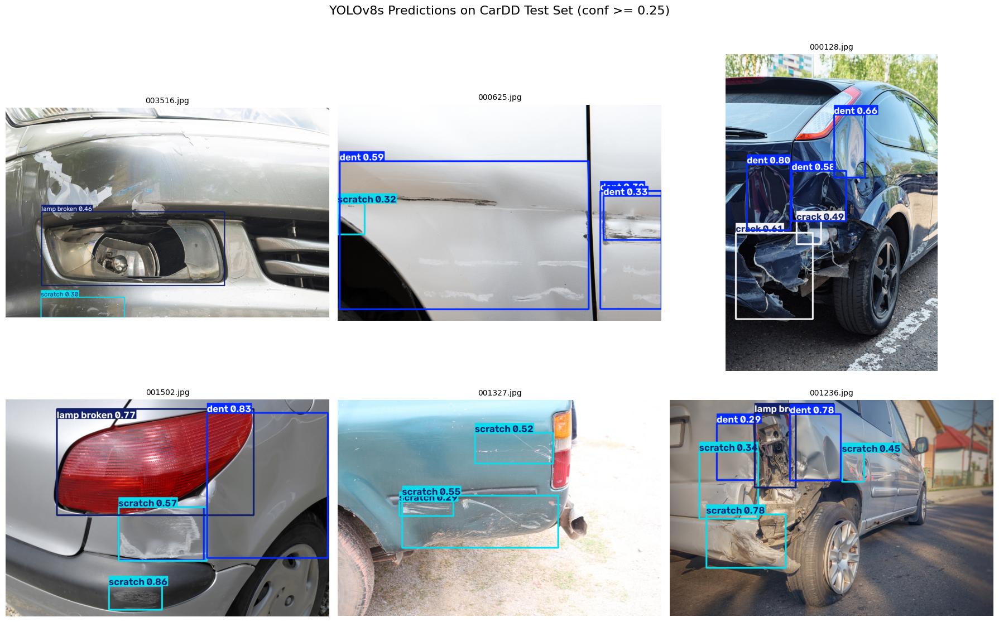

In [9]:
# Cell 9: Predictions on 6 test images
random.seed(42)
test_dir = Path("../data/processed/cardd_yolo/images/test")
test_samples = random.sample(list(test_dir.glob("*.jpg")), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("YOLOv8s Predictions on CarDD Test Set (conf >= 0.25)", fontsize=16, y=1.0)

for ax, img_path in zip(axes.flat, test_samples):
    results = model_best.predict(str(img_path), conf=0.25, verbose=False)
    for r in results:
        im_array = r.plot()
        ax.imshow(cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB))
        ax.set_title(img_path.name, fontsize=10)
        ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.savefig("../reports/figures/yolo_test_predictions.png", dpi=110)
plt.show()

In [10]:
# Cell 10: Cache predictions ONCE, choose threshold on val (honest protocol)
# Shared helpers (iou, match_and_stats, test_preds, val_preds) are used by later cells.
BEST_WEIGHTS = Path("../models/yolo/yolov8s_cardd/weights/best.pt")
model = YOLO(str(BEST_WEIGHTS))

# 1. Cache predictions at conf=0.001 (all boxes, no threshold)
def cache_split(split_name):
    cache_path = REPORTS / f"pred_cache_{split_name}.json"
    if cache_path.exists():
        print(f"  {split_name}: loading cache ({cache_path.name})")
        return json.load(open(cache_path))

    split_dir = Path(f"../data/processed/cardd_yolo/images/{split_name}")
    labels_dir = Path(f"../data/processed/cardd_yolo/labels/{split_name}")
    imgs = sorted(split_dir.glob("*.jpg"))
    print(f"  {split_name}: inferring on {len(imgs)} images...")

    preds = []
    for img_path in imgs:
        # Ground truth
        lbl_path = labels_dir / (img_path.stem + ".txt")
        gt = []
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                if line.strip():
                    parts = line.split()
                    gt.append({"cls": int(parts[0]),
                               "x": float(parts[1]), "y": float(parts[2]),
                               "w": float(parts[3]), "h": float(parts[4])})
        # Predictions at conf=0.001 (capture ALL boxes)
        r = model.predict(str(img_path), conf=0.001, verbose=False)[0]
        h, w = r.orig_shape
        pred = [{"cls": int(b.cls[0]), "conf": float(b.conf[0]),
                 "x": ((b.xyxy[0][0]+b.xyxy[0][2])/2).item()/w,
                 "y": ((b.xyxy[0][1]+b.xyxy[0][3])/2).item()/h,
                 "w": (b.xyxy[0][2]-b.xyxy[0][0]).item()/w,
                 "h": (b.xyxy[0][3]-b.xyxy[0][1]).item()/h}
                for b in r.boxes]
        preds.append({"image": img_path.name, "gt": gt, "pred": pred})

    json.dump(preds, open(cache_path, "w"))
    print(f"  {split_name}: cached {len(preds)} images")
    return preds

print("Caching predictions (conf=0.001, once)...")
val_preds = cache_split("val")
test_preds = cache_split("test")

# 2. IoU + match helper
def iou(a, b):
    x1 = max(a["x"]-a["w"]/2, b["x"]-b["w"]/2)
    y1 = max(a["y"]-a["h"]/2, b["y"]-b["h"]/2)
    x2 = min(a["x"]+a["w"]/2, b["x"]+b["w"]/2)
    y2 = min(a["y"]+a["h"]/2, b["y"]+b["h"]/2)
    inter = max(0, x2-x1) * max(0, y2-y1)
    union = a["w"]*a["h"] + b["w"]*b["h"] - inter
    return inter/union if union > 0 else 0

def match_and_stats(preds, conf_thr, iou_thr=0.5):
    """Per-class TP/FP/FN at given confidence threshold."""
    stats = {i: {"tp": 0, "fp": 0, "fn": 0} for i in range(6)}
    for item in preds:
        gt, used = item["gt"], [False]*len(item["gt"])
        pred = [p for p in item["pred"] if p["conf"] >= conf_thr]
        for p in sorted(pred, key=lambda x: -x["conf"]):
            best_iou, best_j = 0, -1
            for j, g in enumerate(gt):
                if used[j] or g["cls"] != p["cls"]: continue
                v = iou(g, p)
                if v > best_iou: best_iou, best_j = v, j
            if best_iou >= iou_thr and best_j >= 0:
                stats[p["cls"]]["tp"] += 1; used[best_j] = True
            else:
                stats[p["cls"]]["fp"] += 1
        for j, g in enumerate(gt):
            if not used[j]: stats[g["cls"]]["fn"] += 1
    return stats

# 3. Sweep threshold on VALIDATION only
print("\nSweeping threshold on validation (cached, no re-inference)...")
sweep_rows = []
for thr in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60]:
    s = match_and_stats(val_preds, thr)
    tp = sum(v["tp"] for v in s.values())
    fp = sum(v["fp"] for v in s.values())
    fn = sum(v["fn"] for v in s.values())
    p = tp/(tp+fp) if tp+fp else 0
    r = tp/(tp+fn) if tp+fn else 0
    f1 = 2*p*r/(p+r) if p+r else 0
    sweep_rows.append({"thr": thr, "P": p, "R": r, "F1": f1, "TP": tp, "FP": fp, "FN": fn})

df_sweep = pd.DataFrame(sweep_rows)
print(df_sweep.round(4).to_string(index=False))

best_thr = df_sweep.loc[df_sweep["F1"].idxmax(), "thr"]
print(f"\nChosen threshold (val micro-F1 argmax): {best_thr}")

# Save the threshold
p_path = Path("../params.yaml")
params = yaml.safe_load(open(p_path)) if p_path.exists() else {}
params = params or {}
params.setdefault("detection", {})["confidence_threshold"] = float(best_thr)
yaml.dump(params, open(p_path, "w"), default_flow_style=False)

df_sweep.to_csv(REPORTS / "val_threshold_sweep_honest.csv", index=False)
print(f"Saved to {REPORTS/'val_threshold_sweep_honest.csv'}")

Caching predictions (conf=0.001, once)...
  val: loading cache (pred_cache_val.json)
  test: loading cache (pred_cache_test.json)

Sweeping threshold on validation (cached, no re-inference)...
 thr      P      R     F1   TP   FP  FN
0.05 0.3738 0.7437 0.4975 1297 2173 447
0.10 0.4632 0.6967 0.5564 1215 1408 529
0.15 0.5244 0.6709 0.5887 1170 1061 574
0.20 0.5707 0.6456 0.6059 1126  847 618
0.25 0.6217 0.6267 0.6242 1093  665 651
0.30 0.6554 0.6095 0.6316 1063  559 681
0.40 0.7094 0.5642 0.6286  984  403 760
0.50 0.7623 0.5241 0.6211  914  285 830
0.60 0.8269 0.4656 0.5957  812  170 932

Chosen threshold (val micro-F1 argmax): 0.3
Saved to ..\reports\metrics\val_threshold_sweep_honest.csv


--- Test at val-chosen threshold 0.3 (applied ONCE) ---
        class  tp  fp  fn  precision  recall     f1
         dent 145  75  91     0.6591  0.6144 0.6360
      scratch 191 122 116     0.6102  0.6221 0.6161
        crack  30  28  40     0.5172  0.4286 0.4688
glass shatter  70   5   1     0.9333  0.9859 0.9589
  lamp broken  57  16  12     0.7808  0.8261 0.8028
    tire flat  26   5   6     0.8387  0.8125 0.8254

Overall: P=0.6740  R=0.6611  F1=0.6675


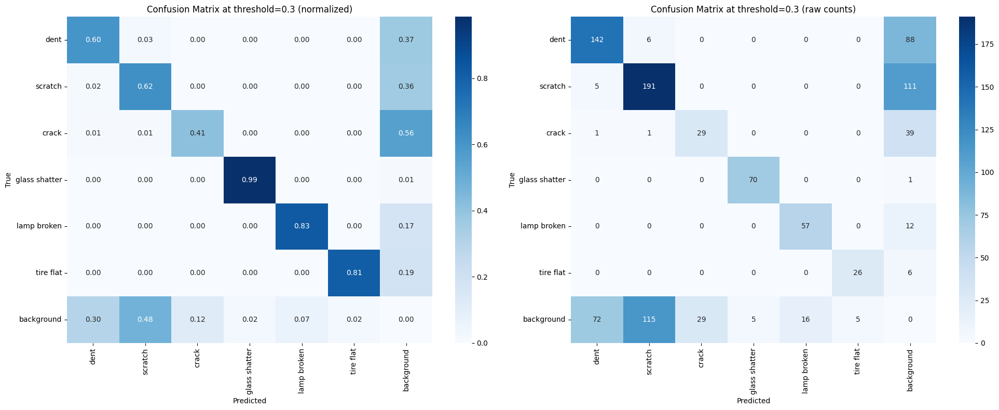


--- Confusion matrix at threshold 0.3 ---
Background row (FP) per class:
  dent           :   72 false positives
  scratch        :  115 false positives
  crack          :   29 false positives
  glass shatter  :    5 false positives
  lamp broken    :   16 false positives
  tire flat      :    5 false positives

Background column (misses) per class:
  dent           :   88/236 missed (37.3%)
  scratch        :  111/307 missed (36.2%)
  crack          :   39/70 missed (55.7%)
  glass shatter  :    1/71 missed (1.4%)
  lamp broken    :   12/69 missed (17.4%)
  tire flat      :    6/32 missed (18.8%)


In [11]:
# Cell 11: Test metrics + confusion matrix at the val-chosen threshold

# 1. Test metrics at chosen threshold
test_stats = match_and_stats(test_preds, best_thr)
test_prf = pd.DataFrame([
    {"class": CLASS_NAMES[i],
     "tp": test_stats[i]["tp"], "fp": test_stats[i]["fp"], "fn": test_stats[i]["fn"],
     "precision": test_stats[i]["tp"]/max(1, test_stats[i]["tp"]+test_stats[i]["fp"]),
     "recall": test_stats[i]["tp"]/max(1, test_stats[i]["tp"]+test_stats[i]["fn"]),
     "f1": 2*test_stats[i]["tp"]/max(1, 2*test_stats[i]["tp"]+test_stats[i]["fp"]+test_stats[i]["fn"])}
    for i in range(6)
])

tp = sum(v["tp"] for v in test_stats.values())
fp = sum(v["fp"] for v in test_stats.values())
fn = sum(v["fn"] for v in test_stats.values())
micro_p = tp/(tp+fp) if tp+fp else 0
micro_r = tp/(tp+fn) if tp+fn else 0
micro_f1 = 2*micro_p*micro_r/(micro_p+micro_r) if micro_p+micro_r else 0

print(f"--- Test at val-chosen threshold {best_thr} (applied ONCE) ---")
print(test_prf.round(4).to_string(index=False))
print(f"\nOverall: P={micro_p:.4f}  R={micro_r:.4f}  F1={micro_f1:.4f}")
test_prf.to_csv(REPORTS / "test_prf_honest.csv", index=False)

# 2. Confusion matrix AT the chosen threshold
def confusion_at_threshold(preds, conf_thr, iou_thr=0.5):
    n = 6
    cm = np.zeros((n+1, n+1), dtype=int)   # Last row/col = background
    for item in preds:
        gt, used = item["gt"], [False]*len(item["gt"])
        pred = [p for p in item["pred"] if p["conf"] >= conf_thr]
        for p in sorted(pred, key=lambda x: -x["conf"]):
            best_iou, best_j = 0, -1
            for j, g in enumerate(gt):
                if used[j]: continue
                v = iou(g, p)
                if v > best_iou: best_iou, best_j = v, j
            if best_iou >= iou_thr and best_j >= 0:
                cm[gt[best_j]["cls"], p["cls"]] += 1
                used[best_j] = True
            else:
                cm[n, p["cls"]] += 1          # FP: background -> pred_class
        for j, g in enumerate(gt):
            if not used[j]:
                cm[g["cls"], n] += 1          # FN: true_class -> background
    return cm

cm = confusion_at_threshold(test_preds, best_thr)
labels = CLASS_NAMES + ["background"]
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title(f"Confusion Matrix at threshold={best_thr} (normalized)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title(f"Confusion Matrix at threshold={best_thr} (raw counts)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")

plt.tight_layout()
plt.savefig("../reports/figures/detection/confusion_at_honest_threshold.png", dpi=110)
plt.show()

print(f"\n--- Confusion matrix at threshold {best_thr} ---")
print("Background row (FP) per class:")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {name:15s}: {cm[6, i]:4d} false positives")

print("\nBackground column (misses) per class:")
for i, name in enumerate(CLASS_NAMES):
    n = cm[i, :].sum()
    print(f"  {name:15s}: {cm[i, 6]:4d}/{n} missed ({cm[i,6]/max(1,n)*100:.1f}%)")

In [12]:
# Cell 12: Latency benchmark (end-to-end predict() incl. image read, warm-up, 200 runs)
test_img = list((Path("../data/processed/cardd_yolo/images/test")).glob("*.jpg"))[0]
print(f"Benchmark image: {test_img.name}")

# Warm-up (20 runs)
print("Warming up...")
for _ in range(20):
    _ = model.predict(str(test_img), conf=best_thr, verbose=False)

# Timed runs (200 iterations)
print("Timing 200 runs...")
latencies = []
for _ in range(200):
    t0 = time.perf_counter()
    _ = model.predict(str(test_img), conf=best_thr, verbose=False)
    t1 = time.perf_counter()
    latencies.append((t1 - t0) * 1000)

latencies = np.array(latencies)
print(f"\n--- Latency Benchmark (n=200, RTX 3050, threshold={best_thr}) ---")
print(f"Mean:   {latencies.mean():.2f} ms")
print(f"Median: {np.median(latencies):.2f} ms")
print(f"Std:    {latencies.std():.2f} ms")
print(f"Min:    {latencies.min():.2f} ms")
print(f"P95:    {np.percentile(latencies, 95):.2f} ms")
print(f"P99:    {np.percentile(latencies, 99):.2f} ms")
print(f"FPS:    {1000 / np.median(latencies):.1f}")

Benchmark image: 000012.jpg
Warming up...
Timing 200 runs...

--- Latency Benchmark (n=200, RTX 3050, threshold=0.3) ---
Mean:   22.96 ms
Median: 21.90 ms
Std:    3.00 ms
Min:    20.82 ms
P95:    30.85 ms
P99:    33.43 ms
FPS:    45.7


In [13]:
# Cell 13: Image-level analysis (sweep on Kaggle val, apply once to Kaggle test)

# 1. Load classifier
cls_model = models.resnet18(weights=None)
cls_model.fc = nn.Linear(cls_model.fc.in_features, 2)
cls_model.load_state_dict(torch.load("../models/classification/exp03_resnet18_finetuned.pth", weights_only=True))
cls_model = cls_model.to(device).eval()

tf = transforms.Compose([
    transforms.Resize((256, 256)), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 2. Detector image-level score = max box confidence per image
def image_det_score(preds):
    """Max box confidence per image."""
    return {item["image"]: max([p["conf"] for p in item["pred"]], default=0) for item in preds}

# 3. Kaggle val + test whole cars / damaged (for sweep and final)
PROCESSED = Path("../data/processed")
KAGGLE_DIR = Path("../data/raw/data1a")
df_val_k = pd.read_csv(PROCESSED / "val_split.csv")
df_test_k = pd.read_csv(PROCESSED / "test_split.csv")

def score_whole(df_split):
    scores = []
    for _, row in df_split.iterrows():
        img_path = KAGGLE_DIR / row["image_path"]
        if not img_path.exists(): continue
        r = model.predict(str(img_path), conf=0.01, verbose=False)[0]
        det_max = max([float(b.conf[0]) for b in r.boxes], default=0)
        img = Image.open(img_path).convert("RGB")
        x = tf(img).unsqueeze(0).to(device)
        with torch.no_grad():
            cls_prob = torch.softmax(cls_model(x), 1)[0, 1].item()
        scores.append({"image": row["image_path"], "target": int(row["target"]),
                       "det_score": det_max, "clf_prob": cls_prob})
    return pd.DataFrame(scores)

print("Scoring Kaggle val (for threshold selection)...")
val_k = score_whole(df_val_k)
print("Scoring Kaggle test (for final report)...")
test_k = score_whole(df_test_k)

# 4. Sweep image threshold on VALIDATION (false-alarm rate on whole + recall on damaged)
print("\n--- Image-Level Threshold Sweep (on Kaggle val) ---")
val_whole = val_k[val_k["target"] == 0]
val_dam = val_k[val_k["target"] == 1]

sweep_rows = []
for thr in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    fa = (val_whole["det_score"] >= thr).mean()
    rec = (val_dam["det_score"] >= thr).mean()
    sweep_rows.append({"thr": thr, "FA_on_whole": fa, "Recall_on_damaged": rec})

df_sweep_img = pd.DataFrame(sweep_rows)
print(df_sweep_img.round(3).to_string(index=False))

# Choose threshold: max recall subject to FA <= 0.20
candidates = df_sweep_img[df_sweep_img["FA_on_whole"] <= 0.20]
if len(candidates) > 0:
    tau_img = candidates.loc[candidates["Recall_on_damaged"].idxmax(), "thr"]
else:
    tau_img = df_sweep_img.loc[df_sweep_img["FA_on_whole"].idxmin(), "thr"]
print(f"\nChosen image-level threshold: {tau_img}")

# 5. Report test (once, chosen threshold)
print(f"\n--- Test at image threshold {tau_img} ---")
det_decision_test = test_k["det_score"] >= tau_img
clf_decision_test = test_k["clf_prob"] >= 0.25

print(f"\nDetector alone:   FA={det_decision_test[test_k.target==0].mean():.3f}, Recall={det_decision_test[test_k.target==1].mean():.3f}")
print(f"Classifier alone: FA={clf_decision_test[test_k.target==0].mean():.3f}, Recall={clf_decision_test[test_k.target==1].mean():.3f}")

# Combination rules
and_decision = det_decision_test & clf_decision_test
or_decision = det_decision_test | clf_decision_test
print(f"\nAND (det AND clf): FA={and_decision[test_k.target==0].mean():.3f}, Recall={and_decision[test_k.target==1].mean():.3f}")
print(f"OR  (det OR clf):  FA={or_decision[test_k.target==0].mean():.3f}, Recall={or_decision[test_k.target==1].mean():.3f}")

# CarDD side (all damaged)
print(f"\n--- CarDD test (all damaged) ---")
cardd_imgs = sorted(Path("../data/processed/cardd_yolo/images/test").glob("*.jpg"))
det_scores_cardd = image_det_score(test_preds)
det_hits = sum(1 for p in cardd_imgs if det_scores_cardd.get(p.name, 0) >= tau_img)
print(f"Detector recall on CarDD: {det_hits}/{len(cardd_imgs)} = {det_hits/len(cardd_imgs):.3f}")

# Save the choice
p = Path("../params.yaml")
params = yaml.safe_load(open(p)) if p.exists() else {}
params = params or {}
params.setdefault("detection", {})["image_level_threshold"] = float(tau_img)
yaml.dump(params, open(p, "w"), default_flow_style=False)
df_sweep_img.to_csv(REPORTS / "image_threshold_sweep.csv", index=False)

Scoring Kaggle val (for threshold selection)...
Scoring Kaggle test (for final report)...

--- Image-Level Threshold Sweep (on Kaggle val) ---
 thr  FA_on_whole  Recall_on_damaged
 0.3        0.494              0.614
 0.4        0.384              0.468
 0.5        0.262              0.357
 0.6        0.192              0.263
 0.7        0.110              0.181
 0.8        0.029              0.070

Chosen image-level threshold: 0.6

--- Test at image threshold 0.6 ---

Detector alone:   FA=0.149, Recall=0.279
Classifier alone: FA=0.069, Recall=0.971

AND (det AND clf): FA=0.017, Recall=0.279
OR  (det OR clf):  FA=0.201, Recall=0.971

--- CarDD test (all damaged) ---
Detector recall on CarDD: 333/374 = 0.890


In [14]:
# Cell 14: Miss anatomy (per class, at the chosen threshold)
def miss_anatomy(preds, tau=0.30):
    rows = []
    for item in preds:
        for g in item["gt"]:
            c = g["cls"]
            overlaps = [(iou(g, p), p["cls"], p["conf"]) for p in item["pred"]]

            # Classify the miss
            if any(o >= 0.5 and pc == c and conf >= tau for o, pc, conf in overlaps):
                kind = "found"
            elif any(o >= 0.5 and pc != c and conf >= tau for o, pc, conf in overlaps):
                kind = "wrong class"
            elif any(o >= 0.5 and pc == c for o, pc, conf in overlaps):
                kind = "low confidence"
            elif any(o >= 0.1 and pc == c and conf >= tau for o, pc, conf in overlaps):
                kind = "mislocalized"
            else:
                kind = "nothing overlaps"
            rows.append((CLASS_NAMES[c], kind))

    df = pd.DataFrame(rows, columns=["class", "outcome"])
    ct = pd.crosstab(df["class"], df["outcome"])
    for col in ["found", "wrong class", "low confidence", "mislocalized", "nothing overlaps"]:
        if col not in ct.columns: ct[col] = 0
    return ct[["found", "wrong class", "low confidence", "mislocalized", "nothing overlaps"]]

print(f"--- Miss Anatomy (test, threshold={best_thr}) ---")
print(miss_anatomy(test_preds, tau=best_thr).to_string())

print("\nInterpretation:")
print("  'found'            = TP (approximate, ignores one-to-one matching)")
print("  'low confidence'   = model sees it but ranks below threshold")
print("  'mislocalized'     = box IoU 0.1-0.5 (partial overlap only)")
print("  'nothing overlaps' = model doesn't see damage at all")

--- Miss Anatomy (test, threshold=0.3) ---
outcome        found  wrong class  low confidence  mislocalized  nothing overlaps
class                                                                            
crack             30            1              26             4                 9
dent             145            5              56            20                10
glass shatter     70            0               0             0                 1
lamp broken       57            0               9             1                 2
scratch          191            5              90             9                12
tire flat         26            0               3             0                 3

Interpretation:
  'found'            = TP (approximate, ignores one-to-one matching)
  'low confidence'   = model sees it but ranks below threshold
  'mislocalized'     = box IoU 0.1-0.5 (partial overlap only)
  'nothing overlaps' = model doesn't see damage at all


In [15]:
# Cell 15: Miss anatomy by size (tests if resolution is the bottleneck)
def _kind(item, gt_idx, tau):
    g = item["gt"][gt_idx]
    c = g["cls"]
    overlaps = [(iou(g, p), p["cls"], p["conf"]) for p in item["pred"]]
    if any(o >= 0.5 and pc == c and conf >= tau for o, pc, conf in overlaps):
        return "found"
    if any(o >= 0.5 and pc != c and conf >= tau for o, pc, conf in overlaps):
        return "wrong class"
    if any(o >= 0.5 and pc == c for o, pc, conf in overlaps):
        return "low confidence"
    if any(o >= 0.1 and pc == c and conf >= tau for o, pc, conf in overlaps):
        return "mislocalized"
    return "nothing overlaps"

def miss_anatomy_by_size(preds, tau, edges=(0, 25, 50, 100, 1e9), labels=("<25 px", "25-50", "50-100", ">100")):
    rows = []
    for item in preds:
        for g_idx in range(len(item["gt"])):
            g = item["gt"][g_idx]
            # GT is normalized: short side as a fraction of the image -> "640-pixel equivalent"
            short_640 = min(g["w"], g["h"]) * 640
            rows.append((short_640, _kind(item, g_idx, tau)))

    df = pd.DataFrame(rows, columns=["short_side_640px", "outcome"])
    df["size"] = pd.cut(df.short_side_640px, bins=list(edges), labels=list(labels))
    tab = pd.crosstab(df["size"], df["outcome"])
    cols = ["found", "wrong class", "low confidence", "mislocalized", "nothing overlaps"]
    for c in cols:
        if c not in tab: tab[c] = 0
    tab = tab[cols]
    tab.insert(0, "n", tab.sum(axis=1))
    tab["found %"] = (100 * tab["found"] / tab["n"]).round(0)
    return tab

print(f"--- Miss Anatomy by Size (test, threshold={best_thr}) ---")
print("Short side in 640px-equivalent units")
tab_size = miss_anatomy_by_size(test_preds, tau=best_thr)
print(tab_size.to_string())

print("\nInterpretation:")
print("  If 'low confidence' and 'nothing overlaps' concentrate in <25px -> resolution IS the bottleneck")
print("  If they're spread evenly -> resolution is not the only issue; look at labels / training length")

--- Miss Anatomy by Size (test, threshold=0.3) ---
Short side in 640px-equivalent units
outcome    n  found  wrong class  low confidence  mislocalized  nothing overlaps  found %
size                                                                                     
<25 px    30      9            0               7             2                12     30.0
25-50     69     24            0              35             2                 8     35.0
50-100   161     84            3              57            10                 7     52.0
>100     525    402            8              85            20                10     77.0

Interpretation:
  If 'low confidence' and 'nothing overlaps' concentrate in <25px -> resolution IS the bottleneck
  If they're spread evenly -> resolution is not the only issue; look at labels / training length


In [16]:
# Cell 16: Detector vs classifier AUC + agreement analysis (Kaggle test)
from sklearn.metrics import roc_auc_score

PROCESSED = Path("../data/processed")
KAGGLE_DIR = Path("../data/raw/data1a")

# Image-level threshold chosen on validation in Cell 13
tau_img = yaml.safe_load(open("../params.yaml"))["detection"]["image_level_threshold"]

# 1. Score Kaggle test with both models
df_test_k = pd.read_csv(PROCESSED / "test_split.csv")
df_test_k = df_test_k[df_test_k["image_path"].apply(lambda p: (KAGGLE_DIR / p).exists())]

scores = []
for _, row in df_test_k.iterrows():
    img_path = KAGGLE_DIR / row["image_path"]

    # Detector
    r = model.predict(str(img_path), conf=0.01, verbose=False)[0]
    det_max = max([float(b.conf[0]) for b in r.boxes], default=0)

    # Classifier
    img = Image.open(img_path).convert("RGB")
    x = tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        cls_prob = torch.softmax(cls_model(x), 1)[0, 1].item()

    scores.append({"target": int(row["target"]), "det_score": det_max, "clf_prob": cls_prob})

te = pd.DataFrame(scores)

# 2. AUC comparison
det_auc = roc_auc_score(te["target"], te["det_score"])
clf_auc = roc_auc_score(te["target"], te["clf_prob"])
print(f"--- Kaggle test AUC (n={len(te)}) ---")
print(f"Detector:   {det_auc:.3f}")
print(f"Classifier: {clf_auc:.3f}")

# 3. 2x2 agreement tables
clf_pred = te["clf_prob"] >= 0.25
det_pred = te["det_score"] >= tau_img

print(f"\n--- 2x2 Agreement (Kaggle test, tau_img={tau_img}) ---")
print(pd.crosstab(
    [te["target"].map({0: "whole", 1: "damaged"}), clf_pred.rename("clf_says_damaged")],
    det_pred.rename("det_says_damaged"),
    margins=True
))

# Disagreement count (review flag trigger)
disagreements = (clf_pred != det_pred).sum()
print(f"\nDisagreement cases (would trigger review): {disagreements}/{len(te)} = {disagreements/len(te):.1%}")

# 4. Who is right when they agree / disagree
truth = te["target"] == 1
clf_ok = clf_pred == truth
det_ok = det_pred == truth
print(f"\n--- Correctness breakdown ---")
print(f"Both correct:              {(clf_ok & det_ok).sum()}")
print(f"Only classifier correct:   {(clf_ok & ~det_ok).sum()}")
print(f"Only detector correct:     {(~clf_ok & det_ok).sum()}")
print(f"Both wrong:                {(~clf_ok & ~det_ok).sum()}")

# Save
te.to_csv(REPORTS / "kaggle_test_scores_agreement.csv", index=False)
print(f"\nSaved to {REPORTS/'kaggle_test_scores_agreement.csv'}")

--- Kaggle test AUC (n=346) ---
Detector:   0.640
Classifier: 0.993

--- 2x2 Agreement (Kaggle test, tau_img=0.6) ---
det_says_damaged          False  True  All
target  clf_says_damaged                  
damaged False                 5     0    5
        True                119    48  167
whole   False               139    23  162
        True                  9     3   12
All                         272    74  346

Disagreement cases (would trigger review): 151/346 = 43.6%

--- Correctness breakdown ---
Both correct:              187
Only classifier correct:   142
Only detector correct:     9
Both wrong:                8

Saved to ..\reports\metrics\kaggle_test_scores_agreement.csv


In [17]:
# Cell 17: Final threshold consistency + recomputed false-alarm / recall numbers

FINAL_THR = 0.30
REPORTS = Path("../reports/metrics")
KAGGLE_DIR = Path("../data/raw/data1a")
CARDD_TEST = Path("../data/processed/cardd_yolo/images/test")
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. params.yaml must say 0.30
params = yaml.safe_load(open("../params.yaml")) or {}
print("params.yaml detection:", params.get("detection"))
if params.get("detection", {}).get("confidence_threshold") != FINAL_THR:
    params.setdefault("detection", {})["confidence_threshold"] = FINAL_THR
    yaml.dump(params, open("../params.yaml", "w"), default_flow_style=False)
    print("-> corrected to", FINAL_THR)

# 2. Classifier + transform
cls_model = models.resnet18(weights=None)
cls_model.fc = nn.Linear(cls_model.fc.in_features, 2)
cls_model.load_state_dict(torch.load("../models/classification/exp03_resnet18_finetuned.pth", weights_only=True))
cls_model = cls_model.to(device).eval()
tf = transforms.Compose([
    transforms.Resize((256, 256)), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def clf_prob(img_path):
    x = tf(Image.open(img_path).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        return torch.softmax(cls_model(x), 1)[0, 1].item()

# 3. Whole cars (negatives) from Kaggle test
df = pd.read_csv("../data/processed/test_split.csv")
whole = df[(df["target"] == 0) & df["image_path"].apply(lambda p: (KAGGLE_DIR / p).exists())]
det_fa, cls_fa, fa_examples = 0, 0, []
for _, row in whole.iterrows():
    p = KAGGLE_DIR / row["image_path"]
    r = model.predict(str(p), conf=FINAL_THR, verbose=False)[0]
    if len(r.boxes) > 0:
        det_fa += 1
        if len(fa_examples) < 10:
            fa_examples.append({"image": str(row["image_path"]), "n": len(r.boxes),
                                "top": [(r.names[int(b.cls[0])], round(float(b.conf[0]), 3)) for b in r.boxes][:3]})
    if clf_prob(p) >= 0.25:
        cls_fa += 1
n_w = len(whole)

# 4. CarDD test (all damaged): recall
cardd = sorted(CARDD_TEST.glob("*.jpg"))
det_hit = cls_hit = 0
for p in cardd:
    r = model.predict(str(p), conf=FINAL_THR, verbose=False)[0]
    det_hit += len(r.boxes) > 0
    cls_hit += clf_prob(p) >= 0.25
n_d = len(cardd)

print(f"\n=== Whole-car negatives (n={n_w}) at threshold {FINAL_THR} ===")
print(f"Detector false-alarm rate:   {det_fa}/{n_w} = {det_fa/n_w:.1%}")
print(f"Classifier false-alarm rate: {cls_fa}/{n_w} = {cls_fa/n_w:.1%}")
print(f"\n=== CarDD test, all damaged (n={n_d}) ===")
print(f"Detector image recall:   {det_hit}/{n_d} = {det_hit/n_d:.1%}")
print(f"Classifier image recall: {cls_hit}/{n_d} = {cls_hit/n_d:.1%}")

with open(REPORTS / "negative_image_test_final.json", "w") as f:
    json.dump({"threshold": FINAL_THR, "n_whole": n_w, "detector_false_alarms": int(det_fa),
               "classifier_false_alarms": int(cls_fa), "n_cardd": n_d,
               "detector_hits": int(det_hit), "classifier_hits": int(cls_hit),
               "examples": fa_examples}, f, indent=2)
print("Saved negative_image_test_final.json")

params.yaml detection: {'confidence_threshold': 0.3, 'image_level_threshold': 0.6}

=== Whole-car negatives (n=174) at threshold 0.3 ===
Detector false-alarm rate:   80/174 = 46.0%
Classifier false-alarm rate: 12/174 = 6.9%

=== CarDD test, all damaged (n=374) ===
Detector image recall:   368/374 = 98.4%
Classifier image recall: 353/374 = 94.4%
Saved negative_image_test_final.json


In [18]:
# Cell 18: Bootstrap CI using 101-point interpolated AP (same convention as Ultralytics)

REPORTS = Path("../reports/metrics")
CLASS_NAMES = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
ULTRA_MAP50 = 0.7409
ULTRA_AP50 = np.array([0.6385, 0.6325, 0.4381, 0.9821, 0.8643, 0.8902])  # from Cell 8
test_preds = json.load(open(REPORTS / "pred_cache_test.json"))

def iou(a, b):
    x1 = max(a["x"]-a["w"]/2, b["x"]-b["w"]/2); y1 = max(a["y"]-a["h"]/2, b["y"]-b["h"]/2)
    x2 = min(a["x"]+a["w"]/2, b["x"]+b["w"]/2); y2 = min(a["y"]+a["h"]/2, b["y"]+b["h"]/2)
    inter = max(0, x2-x1) * max(0, y2-y1)
    union = a["w"]*a["h"] + b["w"]*b["h"] - inter
    return inter/union if union > 0 else 0

# 1. Per-image, per-class matches (computed ONCE)
per_img = []
for item in test_preds:
    row = {}
    for c in range(6):
        gt = [g for g in item["gt"] if g["cls"] == c]
        used = [False]*len(gt)
        confs, tps = [], []
        for p in sorted((p for p in item["pred"] if p["cls"] == c), key=lambda x: -x["conf"]):
            best, bj = 0, -1
            for j, g in enumerate(gt):
                if used[j]: continue
                v = iou(g, p)
                if v > best: best, bj = v, j
            hit = bj >= 0 and best >= 0.5
            if hit: used[bj] = True
            confs.append(p["conf"]); tps.append(1 if hit else 0)
        row[c] = (np.array(confs), np.array(tps), len(gt))
    per_img.append(row)

# 2. AP from pooled matches
_trapz = getattr(np, "trapezoid", None) or np.trapz
def ap_from(confs, tps, n_gt):
    if n_gt == 0 or len(confs) == 0: return 0.0
    o = np.argsort(-confs); tps = tps[o]
    tpc = np.cumsum(tps); fpc = np.cumsum(1 - tps)
    rec = tpc / n_gt; prec = tpc / np.maximum(tpc + fpc, 1)
    mrec = np.concatenate(([0.0], rec, [1.0])); mpre = np.concatenate(([1.0], prec, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    return _trapz(np.interp(x, mrec, mpre), x)

def eval_idx(idx):
    aps = []
    for c in range(6):
        confs = np.concatenate([per_img[i][c][0] for i in idx])
        tps = np.concatenate([per_img[i][c][1] for i in idx])
        n_gt = sum(per_img[i][c][2] for i in idx)
        aps.append(ap_from(confs, tps, n_gt))
    return np.array(aps)

# 3. Verify against Ultralytics
full = eval_idx(range(len(per_img)))
print(f"Ultralytics test mAP@0.5: {ULTRA_MAP50:.4f}")
print(f"Our 101-pt mAP@0.5:       {full.mean():.4f}   (diff {abs(full.mean()-ULTRA_MAP50):.4f})")

# 4. Bootstrap (image-level)
rng = np.random.default_rng(42)
n = len(per_img)
boot = np.array([eval_idx(rng.integers(0, n, n)) for _ in range(1000)])
bm = boot.mean(1)

lo, hi = np.percentile(bm, [2.5, 97.5])
print(f"\nBootstrap mAP@0.5 mean {bm.mean():.4f}, 95% percentile CI [{lo:.4f}, {hi:.4f}]")
shift = ULTRA_MAP50 - bm.mean()
print(f"Anchored to Ultralytics point (shifted by {shift:+.4f}): [{lo+shift:.4f}, {hi+shift:.4f}]")

print(f"\n{'Class':15s} | {'Ultra AP50':>10s} | {'95% CI (percentile)':>22s}")
for c, name in enumerate(CLASS_NAMES):
    l, h = np.percentile(boot[:, c], [2.5, 97.5])
    print(f"{name:15s} | {ULTRA_AP50[c]:>10.3f} | [{l:.3f}, {h:.3f}]")

Ultralytics test mAP@0.5: 0.7409
Our 101-pt mAP@0.5:       0.7360   (diff 0.0049)

Bootstrap mAP@0.5 mean 0.7380, 95% percentile CI [0.7005, 0.7730]
Anchored to Ultralytics point (shifted by +0.0029): [0.7034, 0.7759]

Class           | Ultra AP50 |    95% CI (percentile)
dent            |      0.638 | [0.566, 0.705]
scratch         |      0.632 | [0.558, 0.666]
crack           |      0.438 | [0.311, 0.576]
glass shatter   |      0.982 | [0.951, 0.994]
lamp broken     |      0.864 | [0.773, 0.939]
tire flat       |      0.890 | [0.761, 0.964]


Total missed GT boxes at tau=0.3: 266  (expected 266 = 785 GT - 519 TP, matches Cell 11 FN total)
kind           low confidence  mislocalized  nothing overlaps
cls                                                          
crack                      26             9                 5
dent                       59            26                 6
glass shatter               0             1                 0
lamp broken                 9             2                 1
scratch                    91            23                 2
tire flat                   3             1                 2


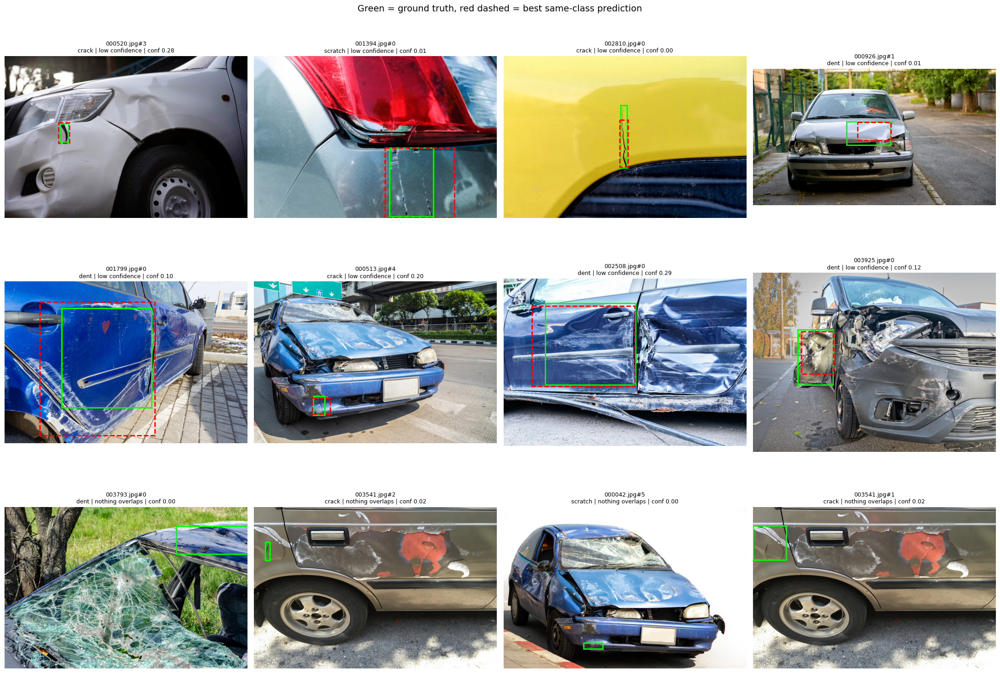


Sample ids: ['000520.jpg#3', '001394.jpg#0', '002810.jpg#0', '000926.jpg#1', '001799.jpg#0', '000513.jpg#4', '002508.jpg#0', '003925.jpg#0', '003793.jpg#0', '003541.jpg#2', '000042.jpg#5', '003541.jpg#1']

Tag counts (n=12, manual review):
ambiguous label                      4
tiny / minimal damage                3
borderline (conf just under 0.30)    2
low-contrast / thin                  2
occluded / edge / cluttered          1


In [20]:
# Cell 19: Low-confidence miss review (only GTs NOT found at tau), with tagging

TAU = 0.30
REPORTS = Path("../reports/metrics")
CARDD_TEST = Path("../data/processed/cardd_yolo/images/test")
CLASS_NAMES = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
test_preds = json.load(open(REPORTS / "pred_cache_test.json"))

def iou(a, b):
    x1 = max(a["x"]-a["w"]/2, b["x"]-b["w"]/2); y1 = max(a["y"]-a["h"]/2, b["y"]-b["h"]/2)
    x2 = min(a["x"]+a["w"]/2, b["x"]+b["w"]/2); y2 = min(a["y"]+a["h"]/2, b["y"]+b["h"]/2)
    inter = max(0, x2-x1) * max(0, y2-y1)
    union = a["w"]*a["h"] + b["w"]*b["h"] - inter
    return inter/union if union > 0 else 0

rows = []
for item in test_preds:
    for gi, g in enumerate(item["gt"]):
        ov = [(iou(g, p), p) for p in item["pred"] if p["cls"] == g["cls"]]
        if any(o >= 0.5 and p["conf"] >= TAU for o, p in ov):
            continue                      # found -> not a miss
        best = max(ov, key=lambda t: t[0], default=(0, None))
        o, p = best
        kind = ("low confidence" if o >= 0.5 else "mislocalized" if o >= 0.1 else "nothing overlaps")
        rows.append({"id": f"{item['image']}#{gi}", "image": item["image"], "cls": g["cls"],
                     "short_640": min(g["w"], g["h"]) * 640, "kind": kind,
                     "best_iou": o, "best_conf": p["conf"] if p else 0, "gt": g, "pred": p})
miss = pd.DataFrame(rows)
print(f"Total missed GT boxes at tau={TAU}: {len(miss)}  (expected 266 = 785 GT - 519 TP, matches Cell 11 FN total)")
print(pd.crosstab(miss["cls"].map(lambda c: CLASS_NAMES[c]), miss["kind"]).to_string())

# Visual sample: 8 low-confidence + 4 nothing-overlaps (dent/scratch/crack only)
random.seed(42)
pool_lc = miss[(miss.kind == "low confidence") & miss.cls.isin([0, 1, 2])]
pool_no = miss[(miss.kind == "nothing overlaps") & miss.cls.isin([0, 1, 2])]
sample = pd.concat([pool_lc.sample(min(8, len(pool_lc)), random_state=42),
                    pool_no.sample(min(4, len(pool_no)), random_state=42)])

fig, axes = plt.subplots(3, 4, figsize=(22, 16))
for ax, (_, m) in zip(axes.flat, sample.iterrows()):
    img = cv2.cvtColor(cv2.imread(str(CARDD_TEST / m["image"])), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]; ax.imshow(img)
    g = m["gt"]
    ax.add_patch(plt.Rectangle(((g["x"]-g["w"]/2)*w, (g["y"]-g["h"]/2)*h), g["w"]*w, g["h"]*h,
                               lw=2, ec="lime", fc="none"))
    if m["pred"] is not None and m["best_iou"] >= 0.1:
        p = m["pred"]
        ax.add_patch(plt.Rectangle(((p["x"]-p["w"]/2)*w, (p["y"]-p["h"]/2)*h), p["w"]*w, p["h"]*h,
                                   lw=2, ec="red", fc="none", ls="--"))
    ax.set_title(f"{m['id']}\n{CLASS_NAMES[m['cls']]} | {m['kind']} | conf {m['best_conf']:.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Green = ground truth, red dashed = best same-class prediction", fontsize=14)
plt.tight_layout()
plt.savefig("../reports/figures/detection/low_confidence_misses_v2.png", dpi=110)
plt.show()
print("\nSample ids:", list(sample["id"]))

# TAGS: after looking at the figure, fill this in, e.g. {"001506.jpg#0": "a", ...}
# a=low-contrast/thin  b=occluded/edge/cluttered  c=ambiguous label  d=tiny/minimal damage  e=borderline (box correct, conf just under 0.30)
TAGS = {
    "000520.jpg#3": "e", "001394.jpg#0": "a", "002810.jpg#0": "a", "000926.jpg#1": "c",
    "001799.jpg#0": "c", "000513.jpg#4": "d", "002508.jpg#0": "e", "003925.jpg#0": "c",
    "003793.jpg#0": "b", "003541.jpg#2": "d", "000042.jpg#5": "d", "003541.jpg#1": "c",
}
TAG_NAMES = {"a": "low-contrast / thin", "b": "occluded / edge / cluttered", "c": "ambiguous label",
             "d": "tiny / minimal damage", "e": "borderline (conf just under 0.30)"}
tag_series = pd.Series(TAGS)
print("\nTag counts (n=%d, manual review):" % len(tag_series))
print(tag_series.map(TAG_NAMES).value_counts().to_string())
tag_series.to_csv(REPORTS / "low_conf_miss_tags.csv", header=["tag"])

In [21]:
# Cell 20: Final artifact check + inference test from the final models/ directory
import ultralytics
FINAL_WEIGHTS = Path("../models/yolo/yolov8s_cardd/weights/best.pt")
assert FINAL_WEIGHTS.exists(), "best.pt missing"

params = yaml.safe_load(open("../params.yaml"))
CONF = float(params["detection"]["confidence_threshold"])
TAU_IMG = float(params["detection"]["image_level_threshold"])

# 1. Load from the final directory
final_model = YOLO(str(FINAL_WEIGHTS))
print(f"Loaded: {FINAL_WEIGHTS.resolve()} ({FINAL_WEIGHTS.stat().st_size/1e6:.1f} MB)")
print("Classes:", final_model.names)
assert list(final_model.names.values()) == CLASS_NAMES, "class order mismatch"

# 2. Inference test on 3 test images
test_imgs = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))
for p_img in test_imgs[:3]:
    r = final_model.predict(str(p_img), conf=CONF, imgsz=640, verbose=False)[0]
    print(f"\n{p_img.name}: {len(r.boxes)} detections")
    for b in r.boxes:
        x1, y1, x2, y2 = [round(float(v), 1) for v in b.xyxy[0]]
        print(f"  {r.names[int(b.cls[0])]:14s} conf={float(b.conf[0]):.3f} box=({x1}, {y1}, {x2}, {y2})")

# 3. Reproducibility: live predictions vs cached predictions (first 25 test images)
cache_by_name = {it["image"]: it for it in test_preds}
mismatch = 0
for p_img in test_imgs[:25]:
    live = len(final_model.predict(str(p_img), conf=CONF, verbose=False)[0].boxes)
    cached = sum(1 for q in cache_by_name[p_img.name]["pred"] if q["conf"] >= CONF)
    mismatch += (live != cached)
print(f"\nLive vs cached detection count mismatches: {mismatch}/25")

# 4. Save inference config for FastAPI
inference_config = {
    "weights": "models/yolo/yolov8s_cardd/weights/best.pt",
    "classes": CLASS_NAMES,
    "imgsz": 640,
    "confidence_threshold": CONF,
    "nms_iou": 0.7,                 # Ultralytics default, used in all evaluations
    "max_det": 300,
    "image_level_threshold": TAU_IMG,
    "classifier_threshold": 0.25,
    "median_latency_ms_rtx3050": round(float(np.median(latencies)), 2),
    "versions": {"ultralytics": ultralytics.__version__, "torch": torch.__version__},
    "notes": ["Detector localizes and classifies damage type; damage types are NOT severity labels.",
              "Detector alone is not a reliable damaged/undamaged gate (46% false alarms on whole cars)."],
}
cfg_path = FINAL_WEIGHTS.parent.parent / "inference_config.json"
json.dump(inference_config, open(cfg_path, "w"), indent=2)
print(f"\nSaved {cfg_path.resolve()}")

# 5. Artifact checklist
artifacts = [
    FINAL_WEIGHTS, cfg_path, Path("../params.yaml"),
    REPORTS / "pred_cache_val.json", REPORTS / "pred_cache_test.json",
    REPORTS / "val_threshold_sweep_honest.csv", REPORTS / "test_prf_honest.csv",
    REPORTS / "image_threshold_sweep.csv", REPORTS / "kaggle_test_scores_agreement.csv",
    REPORTS / "negative_image_test_final.json", REPORTS / "low_conf_miss_tags.csv",
    Path("../reports/figures/yolo_baseline.png"), Path("../reports/figures/yolo_test_predictions.png"),
    Path("../reports/figures/detection/confusion_at_honest_threshold.png"),
    Path("../reports/figures/detection/low_confidence_misses_v2.png"),
]
print("\n--- Artifact checklist ---")
for a in artifacts:
    print(("OK      " if a.exists() else "MISSING ") + str(a))

Loaded: C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\models\yolo\yolov8s_cardd\weights\best.pt (22.5 MB)
Classes: {0: 'dent', 1: 'scratch', 2: 'crack', 3: 'glass shatter', 4: 'lamp broken', 5: 'tire flat'}

000012.jpg: 1 detections
  tire flat      conf=0.886 box=(27.8, 217.6, 364.1, 560.5)

000015.jpg: 1 detections
  scratch        conf=0.492 box=(317.2, 475.0, 998.1, 607.9)

000023.jpg: 2 detections
  dent           conf=0.618 box=(273.6, 169.7, 501.0, 284.2)
  scratch        conf=0.309 box=(541.2, 319.8, 626.0, 405.5)

Live vs cached detection count mismatches: 0/25

Saved C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\models\yolo\yolov8s_cardd\inference_config.json

--- Artifact checklist ---
OK      ..\models\yolo\yolov8s_cardd\weights\best.pt
OK      ..\models\yolo\yolov8s_cardd\inference_config.json
OK      ..\params.yaml
OK      ..\reports\metrics\pred_cache_val.json
OK      ..\reports\metrics\pred_cache_test.json
OK      ..\reports\metrics\val_threshold_sweep_hon

In [22]:
# Cell 21: Final results summary (built from variables computed above, nothing hardcoded)
lo_map, hi_map = np.percentile(bm, [2.5, 97.5])
ci_cls = {CLASS_NAMES[i]: [float(np.percentile(boot[:, i], 2.5)), float(np.percentile(boot[:, i], 97.5))] for i in range(6)}
miss_kinds = miss["kind"].value_counts().to_dict()
size_found = {str(k): float(v) for k, v in tab_size["found %"].items()}
kag_det_recall = float(det_decision_test[test_k.target == 1].mean())
kag_det_fa = float(det_decision_test[test_k.target == 0].mean())
kag_clf_recall = float(clf_decision_test[test_k.target == 1].mean())
kag_clf_fa = float(clf_decision_test[test_k.target == 0].mean())

summary = {
    "model": {"architecture": "YOLOv8s (COCO-pretrained)", "weights": "models/yolo/yolov8s_cardd/weights/best.pt",
              "size_mb": round(FINAL_WEIGHTS.stat().st_size / 1e6, 1), "imgsz": 640, "epochs": 50, "training_hours": 1.193},
    "dataset": {"name": "CarDD", "classes": CLASS_NAMES,
                "splits": {s: len(list((YOLO_DIR / "images" / s).glob("*.jpg"))) for s in ["train", "val", "test"]}},
    "ultralytics_test": {"mAP50": float(test_metrics.box.map50), "mAP50_95": float(test_metrics.box.map),
                         "precision": float(test_metrics.box.mp), "recall": float(test_metrics.box.mr),
                         "per_class_AP50": {CLASS_NAMES[i]: float(test_metrics.box.ap50[i]) for i in range(6)}},
    "bootstrap_mAP50": {"point_ultralytics": float(test_metrics.box.map50), "ci95": [float(lo_map), float(hi_map)],
                        "per_class_ci95": ci_cls, "n_resamples": 1000,
                        "ap_function_gap_vs_ultralytics": float(abs(full.mean() - test_metrics.box.map50))},
    "operating_point": {"confidence_threshold": float(best_thr), "chosen_on": "validation micro-F1 (custom matching, IoU 0.5)",
                        "test_micro_precision": float(micro_p), "test_micro_recall": float(micro_r), "test_micro_f1": float(micro_f1),
                        "test_per_class_f1": {r["class"]: float(r["f1"]) for _, r in test_prf.iterrows()}},
    "miss_anatomy_test": {"total_missed": int(len(miss)), "by_kind": {k: int(v) for k, v in miss_kinds.items()},
                          "found_pct_by_size_640px": size_found},
    "whole_car_negatives": {"n": int(n_w), "detector_false_alarm_rate": float(det_fa / n_w), "classifier_false_alarm_rate": float(cls_fa / n_w)},
    "cardd_image_recall": {"detector": float(det_hit / n_d), "classifier": float(cls_hit / n_d)},
    "kaggle_image_level": {"image_threshold": float(tau_img), "detector_AUC": float(det_auc), "classifier_AUC": float(clf_auc),
                           "detector": {"recall": kag_det_recall, "false_alarm": kag_det_fa},
                           "classifier": {"recall": kag_clf_recall, "false_alarm": kag_clf_fa}},
    "latency_ms": {"median": float(np.median(latencies)), "p95": float(np.percentile(latencies, 95)), "fps": float(1000 / np.median(latencies))},
    "manual_review_tags_n12": {TAG_NAMES[k]: int(v) for k, v in pd.Series(TAGS).value_counts().items()},
}

summary["limitations"] = [
    f"Crack is the weakest class (test AP50 {test_metrics.box.ap50[2]:.3f}, 95% CI {ci_cls['crack'][0]:.2f}-{ci_cls['crack'][1]:.2f}; custom recall {test_prf.loc[2, 'recall']:.2f}).",
    f"Small damage is found far less often: {size_found.get('<25 px', 0):.0f}% under 25px vs {size_found.get('>100', 0):.0f}% over 100px.",
    f"{miss_kinds.get('low confidence', 0)} of {len(miss)} misses ({miss_kinds.get('low confidence', 0)/len(miss):.0%}) are low-confidence detections (model sees the region, scores below {best_thr}).",
    f"Detector false-alarm rate on whole undamaged cars is {det_fa/n_w:.1%}; it must not be used alone as a damaged/undamaged gate.",
    f"Detector transfers poorly to Kaggle-style images (AUC {det_auc:.3f}, recall {kag_det_recall:.1%} at image threshold {tau_img}); the ResNet18 classifier (AUC {clf_auc:.3f}) is the better gate.",
    "Damage classes are damage types, not severity levels; severity and cost need a separate, validated approach.",
    "Manual review of 12 low-confidence misses is a small qualitative sample, not a statistical result.",
]

json.dump(summary, open(REPORTS / "notebook08_final_summary.json", "w"), indent=2)

print("=== NOTEBOOK 08 FINAL SUMMARY ===")
print(f"Model: YOLOv8s, 50 epochs, {summary['model']['size_mb']} MB, splits {summary['dataset']['splits']}")
print(f"Ultralytics test: mAP@0.5={summary['ultralytics_test']['mAP50']:.3f} (95% CI {lo_map:.3f}-{hi_map:.3f}), mAP@0.5:0.95={summary['ultralytics_test']['mAP50_95']:.3f}")
print(f"Operating point {best_thr}: P={micro_p:.3f} R={micro_r:.3f} F1={micro_f1:.3f} (custom matching, test)")
print(f"Whole-car FA: detector {det_fa/n_w:.1%} | classifier {cls_fa/n_w:.1%}")
print(f"Latency: median {np.median(latencies):.1f} ms ({1000/np.median(latencies):.0f} FPS)")
print("\nLimitations:")
for i, s in enumerate(summary["limitations"], 1):
    print(f" {i}. {s}")
print(f"\nSaved {REPORTS / 'notebook08_final_summary.json'}")

=== NOTEBOOK 08 FINAL SUMMARY ===
Model: YOLOv8s, 50 epochs, 22.5 MB, splits {'train': 2816, 'val': 810, 'test': 374}
Ultralytics test: mAP@0.5=0.741 (95% CI 0.701-0.773), mAP@0.5:0.95=0.552
Operating point 0.3: P=0.674 R=0.661 F1=0.668 (custom matching, test)
Whole-car FA: detector 46.0% | classifier 6.9%
Latency: median 21.9 ms (46 FPS)

Limitations:
 1. Crack is the weakest class (test AP50 0.438, 95% CI 0.31-0.58; custom recall 0.43).
 2. Small damage is found far less often: 30% under 25px vs 77% over 100px.
 3. 188 of 266 misses (71%) are low-confidence detections (model sees the region, scores below 0.3).
 4. Detector false-alarm rate on whole undamaged cars is 46.0%; it must not be used alone as a damaged/undamaged gate.
 5. Detector transfers poorly to Kaggle-style images (AUC 0.640, recall 27.9% at image threshold 0.6); the ResNet18 classifier (AUC 0.993) is the better gate.
 6. Damage classes are damage types, not severity levels; severity and cost need a separate, validated

In [23]:
# Cell 22: 
n_gt_total = sum(len(it["gt"]) for it in test_preds)
n_kag_damaged = len(te) - n_w

print("=== NOTEBOOK 08 FINAL SUMMARY ===")
print(f"Model: YOLOv8s, 50 epochs, {summary['model']['size_mb']} MB | CarDD splits {summary['dataset']['splits']}")

print(f"\n[A] BOX-LEVEL DETECTION (CarDD test: {len(test_preds)} images, {n_gt_total} boxes)")
print(f"  Ultralytics: mAP@0.5={summary['ultralytics_test']['mAP50']:.3f} "
      f"(approx. image-level bootstrap 95% CI {lo_map:.3f}-{hi_map:.3f}), mAP@0.5:0.95={summary['ultralytics_test']['mAP50_95']:.3f}")
print(f"  Custom matching at conf {best_thr} (IoU 0.5): P={micro_p:.3f} R={micro_r:.3f} F1={micro_f1:.3f}")
print(f"  Missed boxes: {len(miss)}/{n_gt_total} ({miss_kinds.get('low confidence', 0)} low confidence, "
      f"{miss_kinds.get('mislocalized', 0)} mislocalized, {miss_kinds.get('nothing overlaps', 0)} nothing overlaps)")

print(f"\n[B] IMAGE-LEVEL: is the image damaged? (not box-level)")
print(f"  At box threshold {best_thr}: whole-car false alarms (Kaggle test, n={n_w}): "
      f"detector {det_fa/n_w:.1%} vs classifier {cls_fa/n_w:.1%}")
print(f"  At box threshold {best_thr}: recall on CarDD damaged images (n={n_d}): "
      f"detector {det_hit/n_d:.1%} vs classifier {cls_hit/n_d:.1%}")
print(f"  At image threshold {tau_img} (Kaggle test: {n_w} whole, {n_kag_damaged} damaged): "
      f"detector recall {kag_det_recall:.1%} / FA {kag_det_fa:.1%}; "
      f"classifier recall {kag_clf_recall:.1%} / FA {kag_clf_fa:.1%}")
print(f"  AUC on Kaggle test: detector {det_auc:.3f} vs classifier {clf_auc:.3f}")

print(f"\n[C] SPEED (one image repeated 200x, end-to-end predict() incl. image decoding, RTX 3050 laptop GPU)")
print(f"  Median {np.median(latencies):.1f} ms ({1000/np.median(latencies):.0f} FPS), P95 {np.percentile(latencies, 95):.1f} ms")

print("\nLimitations:")
for i, s in enumerate(summary["limitations"], 1):
    print(f" {i}. {s}")

=== NOTEBOOK 08 FINAL SUMMARY ===
Model: YOLOv8s, 50 epochs, 22.5 MB | CarDD splits {'train': 2816, 'val': 810, 'test': 374}

[A] BOX-LEVEL DETECTION (CarDD test: 374 images, 785 boxes)
  Ultralytics: mAP@0.5=0.741 (approx. image-level bootstrap 95% CI 0.701-0.773), mAP@0.5:0.95=0.552
  Custom matching at conf 0.3 (IoU 0.5): P=0.674 R=0.661 F1=0.668
  Missed boxes: 266/785 (188 low confidence, 62 mislocalized, 16 nothing overlaps)

[B] IMAGE-LEVEL: is the image damaged? (not box-level)
  At box threshold 0.3: whole-car false alarms (Kaggle test, n=174): detector 46.0% vs classifier 6.9%
  At box threshold 0.3: recall on CarDD damaged images (n=374): detector 98.4% vs classifier 94.4%
  At image threshold 0.6 (Kaggle test: 174 whole, 172 damaged): detector recall 27.9% / FA 14.9%; classifier recall 97.1% / FA 6.9%
  AUC on Kaggle test: detector 0.640 vs classifier 0.993

[C] SPEED (one image repeated 200x, end-to-end predict() incl. image decoding, RTX 3050 laptop GPU)
  Median 21.9 ms 

# Notebook 08 Summary: YOLOv8s Vehicle Damage Detection

## Objective
Train an object detector that finds visible vehicle damage, draws bounding boxes, assigns one of
six damage types and gives a confidence score. This notebook covers detection only. Severity,
repair cost and fraud screening come in later notebooks.

## What was done
| Step | Summary |
|---|---|
| Data | CarDD in YOLO format: 2,816 train / 810 val / 374 test images; classes: dent, scratch, crack, glass shatter, lamp broken, tire flat |
| Baseline | COCO-pretrained YOLOv8s predicts irrelevant COCO classes on damage images (expected) |
| Training | YOLOv8s fine-tuned for 50 epochs, 640 px, batch 8, early stopping (patience 15), mosaic/mixup/copy-paste/flip/rotation augmentation, about 1.2 h on an RTX 3050 laptop GPU |
| Evaluation | Standard Ultralytics test evaluation, plus a custom IoU-0.5 matching evaluation at a chosen operating point |
| Threshold | Confidence threshold **0.30** chosen on validation (micro-F1 on cached predictions), then applied once to test |
| Error analysis | Confusion matrix, miss anatomy by class and size, manual review of 12 missed boxes |
| Image-level check | Detector vs ResNet18 classifier on CarDD (all damaged) and Kaggle whole/damaged cars |
| Finalization | Final `best.pt` load test, live-vs-cached prediction check (25/25 identical), inference config and results summary saved |

## Results

### A. Box-level detection (CarDD test, 374 images, 785 boxes)
| Metric | Value |
|---|---|
| mAP@0.5 (Ultralytics) | **0.741** (approx. image-level bootstrap 95% CI 0.70-0.77) |
| mAP@0.5:0.95 (Ultralytics) | 0.552 |
| Precision / Recall at conf 0.30 (custom matching, IoU 0.5) | 0.674 / 0.661 (F1 0.668) |

Ultralytics P/R (0.727 / 0.734) and custom P/R at 0.30 come from different procedures and operating
points, so they are not directly comparable.

| Class | AP@0.5 | Custom F1 @0.30 |
|---|---|---|
| glass shatter | 0.982 | 0.959 |
| tire flat | 0.890 | 0.825 |
| lamp broken | 0.864 | 0.803 |
| dent | 0.639 | 0.636 |
| scratch | 0.633 | 0.616 |
| crack | 0.438 | 0.469 |

### B. Image-level: is the image damaged? (separate from box-level)
| Check | Detector | ResNet18 classifier |
|---|---|---|
| False alarms on 174 whole cars (box threshold 0.30) | 46.0% | 6.9% |
| Recall on CarDD damaged images (n=374) | 98.4% | 94.4% |
| Kaggle test, image threshold 0.6: recall / false alarm | 27.9% / 14.9% | 97.1% / 6.9% |
| Kaggle test AUC | 0.640 | 0.993 |

Combining them did not help: OR gives the classifier's recall with about 3x its false alarms,
and AND drops recall to 27.9%.

### C. Speed
Median about 22 ms per image (about 46 FPS): one image repeated 200 times, end-to-end `predict()`
including image decoding, on an RTX 3050 laptop GPU.

## Error analysis
- 266 of 785 boxes are missed at 0.30: **188 low confidence (71%)**, 62 mislocalized (23%),
  16 nothing overlaps (6%).
- Class confusion is small (dent and scratch are confused 11 times in total). Errors are mostly misses
  and false positives (115 scratch, 72 dent).
- Found rate rises with box size: 30% under 25 px, 35% for 25-50 px, 52% for 50-100 px, 77% above 100 px.
- Manual review of 12 sampled misses: 4 ambiguous label, 3 tiny, 2 low-contrast/thin,
  2 borderline confidence, 1 occluded/edge. This sample is stratified and small, so it is illustrative,
  not a test-set statistic.

## Limitations
1. Crack is the weakest class (AP50 0.44, CI 0.31-0.58).
2. Small damage is detected much less often than large damage.
3. The detector is not a damaged/undamaged gate: 46% false alarms on whole cars and poor transfer
   to Kaggle-style images. Use the classifier for that decision.
4. The six classes are damage types, not severity levels.
5. Results come from one test split; the bootstrap CI is approximate (custom AP function, gap to
   Ultralytics 0.005).

## Artifacts
- `models/yolo/yolov8s_cardd/weights/best.pt` and `inference_config.json`
- `params.yaml` (box threshold 0.30, image threshold 0.6)
- `reports/metrics/` (sweeps, per-class results, whole-car test, final summary JSON)
- `reports/figures/` (baseline, test predictions, confusion matrix, missed-detection review)

## Next
Notebook 09: severity assessment and repair cost estimation.